<a href="https://colab.research.google.com/github/DA-Maximiliano-Berrelleza/Ecommerce-Correlational-Analysis/blob/main/Ecommerce_Correlational_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NovaRetail+ — Análisis de correlaciones del comportamiento del cliente


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**


## Sección 1 - Cargar y explorar el dataset


En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Se revisan la estructura, los tipos de datos y los valores faltantes antes de calcular las correlaciones.


In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Cargar Dataset


In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv(
    "/content/novaretail_comportamiento_clientes_2024.csv"
)
print(
    f"El dataset contiene {df.shape[0]:,} filas "
    f"y {df.shape[1]} columnas."
)
df.info()

El dataset contiene 15,000 filas y 12 columnas.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ 

#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos


### Exploración y Limpieza


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**. No se identificaron valores nulos mediante `df.info()`

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` fue cargada como `float64`; antes de convertirla a entero se verificará que no contenga valores decimales.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.


In [4]:
# Corregir el tipo de dato
edades_con_decimales = (
    df["edad"].dropna() % 1 != 0
).sum()

print("Edades con decimales:", edades_con_decimales)

# Convertir edad a entero únicamente si todos sus valores son enteros
if edades_con_decimales == 0:
    df["edad"] = df["edad"].astype("int64")
    print("La columna edad fue convertida a int64.")
else:
    print("La columna edad no se modificó porque contiene decimales.")

Edades con decimales: 0
La columna edad fue convertida a int64.


In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas


In [6]:
# Estadísticas descriptivas de variables numéricas
variables_numericas = [
    "edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]

df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.262400,11.492378,18.0,30.0000,38.000,46.0000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,23127.0975,30023.745,36768.4400,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,8.0000,10.000,12.0000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,0.0000,1.000,2.0000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,12.3100,19.730,27.2925,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.1000,3.600,4.1000,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,0.0000,30.705,58.2200,244.69


**Diagnóstico inicial de variables numéricas**

- `edad`: los clientes tienen entre **18 y 75 años**, con una mediana de **38 años**. No se identificaron edades fuera de un rango razonable y la variable fue convertida correctamente a entero.
- `nivel_ingreso`: presenta una mediana de **30,023.75** y valores entre **8,000 y 74,790.84**. El promedio de 30,019.70 es cercano a la mediana.
- `visitas_mes`: los clientes registran entre **1 y 25 visitas mensuales**, con una mediana de **10 visitas**.
- `compras_mes`: presenta una mediana de **1 compra** y un máximo de **8**. El primer cuartil es 0, por lo que al menos una cuarta parte de los clientes no registra compras durante el mes.
- `gasto_publicidad_dirigida`: tiene una mediana de **19.73**, con valores entre **0 y 75.51**. Los valores más altos deberán revisarse posteriormente mediante visualizaciones.
- `satisfaccion`: se mantiene dentro de la escala esperada de **1 a 5**, con un promedio de **3.60**.
- `ingreso_anual`: presenta una mediana de **30.71**, un promedio de **36.59** y valores entre **0 y 244.69**. El primer cuartil es 0 y el máximo se encuentra considerablemente por encima del tercer cuartil de 58.22, por lo que será necesario revisar su distribución antes de interpretar correlaciones.


#### Explorar variables binarias


In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles

variables_binarias = ["miembro_premium", "abandono"]

for columna in variables_binarias:
    print(f"\nDistribución de {columna}:")

    resumen = pd.DataFrame({
        "cantidad": df[columna].value_counts().sort_index(),
        "porcentaje": (
            df[columna].value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    })

    display(resumen)



Distribución de miembro_premium:


,cantidad,porcentaje
miembro_premium,,
0,12911,86.07
1,2089,13.93



Distribución de abandono:


,cantidad,porcentaje
abandono,,
0,12739,84.93
1,2261,15.07


**Diagnóstico inicial de variables binarias**

- `miembro_premium`: contiene únicamente los valores 0 y 1. Los clientes sin membresía representan el **86.07%** de la base, mientras que los miembros premium representan el **13.93%**.
- `abandono`: también contiene únicamente los valores 0 y 1. El **15.07%** de los clientes registra abandono y el **84.93%** permanece en la plataforma.

Las dos variables están correctamente codificadas y no requieren transformación. Sin embargo, sus grupos tienen tamaños diferentes, lo que deberá considerarse al interpretar las correlaciones punto-biseriales.


#### Explorar variables categóricas


In [8]:
# Verificar el número de valores únicos por variable categórica
columnas_texto = ["id_cliente", "tipo_dispositivo", "region"]

df[columnas_texto].nunique()

,0
id_cliente,15000
tipo_dispositivo,3
region,4


In [9]:
# Explorar variables categóricas y cómo se distribuyen
variables_categoricas = ["tipo_dispositivo", "region"]

for columna in variables_categoricas:
    print(f"\nDistribución de {columna}:")

    resumen = pd.DataFrame({
        "cantidad": df[columna].value_counts(),
        "porcentaje": (
            df[columna].value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })

    display(resumen)


Distribución de tipo_dispositivo:


,cantidad,porcentaje
tipo_dispositivo,,
móvil,9818,65.45
escritorio,3720,24.80
tablet,1462,9.75



Distribución de region:


,cantidad,porcentaje
region,,
norte,4395,29.30
oeste,3810,25.40
sur,3726,24.84
este,3069,20.46


**Diagnóstico inicial de variables categóricas**

- `id_cliente`: contiene **15,000 valores únicos**, uno por cada registro. Esto confirma que cada fila corresponde a un cliente diferente. La variable se conservará como identificador, pero no se utilizará en las correlaciones.
- `tipo_dispositivo`: móvil es la categoría principal con **65.45%** de los clientes. Le siguen escritorio con **24.80%** y tablet con **9.75%**.
- `region`: la distribución es relativamente equilibrada. Norte concentra el **29.30%**, oeste el **25.40%**, sur el **24.84%** y este el **20.46%**.

No se identificaron categorías adicionales o fuera de lo esperado. Las variables pueden conservarse sin transformación.


### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.


## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.


### Heatmap


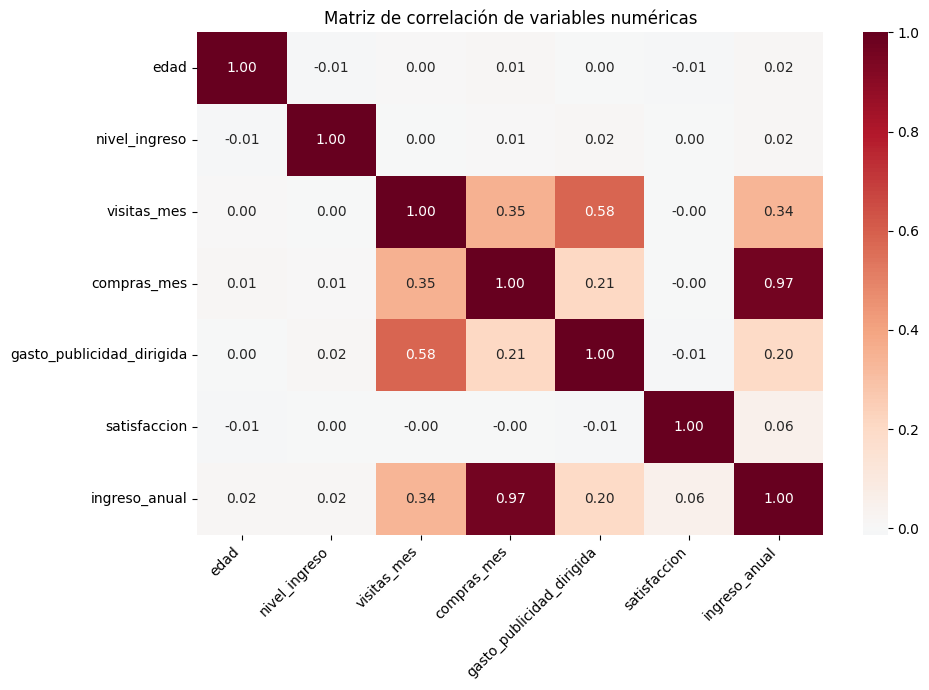

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
matriz_correlacion = df[variables_numericas].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Matriz de correlación de variables numéricas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#### Observaciones generales del heatmap

- La relación positiva más fuerte se presenta entre `compras_mes` e `ingreso_anual`, con una correlación de **0.97**.
- `visitas_mes` y `gasto_publicidad_dirigida` presentan una relación positiva moderada de **0.58**.
- `visitas_mes` también mantiene una relación positiva con `compras_mes`, aunque de menor intensidad, con **0.35**.
- Las demás relaciones son débiles o cercanas a cero. Tampoco se observan correlaciones negativas relevantes.

#### Observaciones respecto a `ingreso_anual`

- `compras_mes` es la variable con mayor relación respecto a `ingreso_anual`, con una correlación positiva de **0.97**.
- `visitas_mes` presenta una correlación positiva de **0.34**, mientras que `gasto_publicidad_dirigida` alcanza **0.20**.
- `edad`, `nivel_ingreso` y `satisfaccion` presentan relaciones cercanas a cero con el ingreso generado.
- Estos resultados muestran asociaciones entre las variables, pero no permiten afirmar que alguna de ellas cause directamente un aumento en `ingreso_anual`.


### Scatterplot general


#### Evaluación del scatterplot general

No se incluye un scatterplot general. Se utiliza el heatmap
como resumen de las correlaciones entre las variables numéricas
y se continúa con scatterplots individuales para los pares clave
seleccionados a partir de sus resultados.

El heatmap permite identificar la fuerza y
dirección de las correlaciones, mientras que los scatterplots
permiten examinar la forma de las relaciones. Los gráficos
individuales complementarán el heatmap mediante la revisión
de tendencias, dispersión y posibles valores atípicos.


### Scatterplot para pares clave


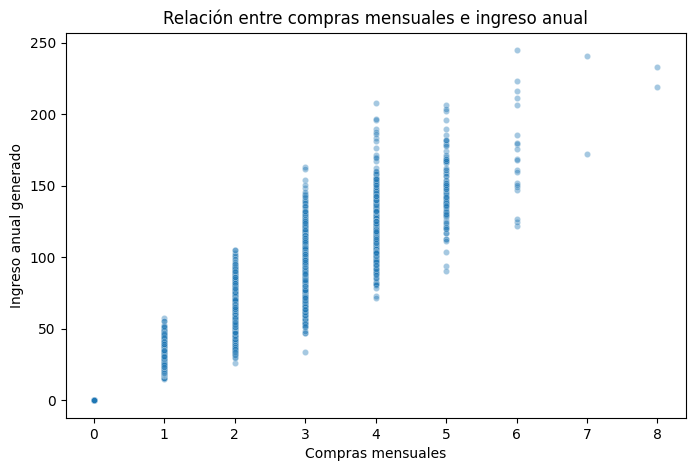

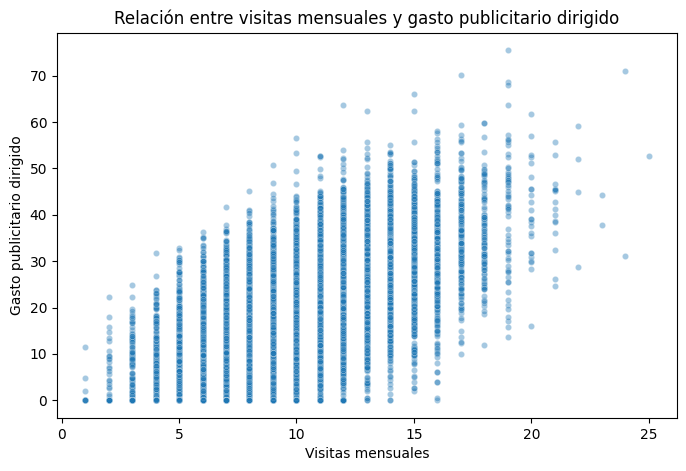

In [11]:
# Visualizar pares de variables con relaciones moderadas o fuertes

# Compras mensuales e ingreso anual
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="compras_mes",
    y="ingreso_anual",
    alpha=0.4,
    s=20
)

plt.title("Relación entre compras mensuales e ingreso anual")
plt.xlabel("Compras mensuales")
plt.ylabel("Ingreso anual generado")
plt.show()

# Visitas mensuales y gasto publicitario dirigido
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="gasto_publicidad_dirigida",
    alpha=0.4,
    s=20
)

plt.title("Relación entre visitas mensuales y gasto publicitario dirigido")
plt.xlabel("Visitas mensuales")
plt.ylabel("Gasto publicitario dirigido")
plt.show()


#### Observaciones iniciales (Scatterplot)

**Compras mensuales vs. ingreso anual**

- **Dirección:** positiva. Los clientes con más compras mensuales tienden a registrar mayor ingreso anual, consistente con la correlación de 0.97 del heatmap.
- **Dispersión:** baja respecto a la tendencia ascendente, aunque el ingreso anual varía entre clientes con el mismo número de compras.
- **Posibles outliers:** se observan pocos clientes con 6 a 8 compras y valores elevados de ingreso. Su ubicación sigue la tendencia general; ser poco frecuentes no basta para clasificarlos como atípicos.
- **Posible colinealidad:** la correlación de **0.97** indica una
  asociación positiva muy fuerte. Sin embargo, este par relaciona
  una variable de comportamiento con la métrica objetivo, por lo
  que no permite evaluar colinealidad entre variables explicativas.
  Conviene verificar si `ingreso_anual` fue construido a partir
  de las compras antes de interpretar esta asociación como
  un hallazgo independiente.

**Visitas mensuales vs. gasto publicitario dirigido**

- **Dirección:** positiva. A mayor número de visitas, el gasto publicitario dirigido tiende a ser mayor, consistente con la correlación de 0.58 del heatmap.
- **Dispersión:** media, con variación amplia del gasto entre clientes que registran el mismo número de visitas.
- **Posibles outliers:** aparecen puntos aislados con gasto superior a 70. Son candidatos a revisión, pero el gráfico por sí solo no confirma que sean atípicos.
- **Posible colinealidad:** no se observa una relación casi perfecta. La correlación de 0.58 y la dispersión visible no sugieren colinealidad fuerte.

Estas asociaciones no permiten afirmar que las compras mensuales
causen el ingreso anual ni que el gasto publicitario cause las visitas.


## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.


### Pearson / Spearman


In [12]:
# Calcular correlación entre variables relevantes
pearson_compras_ingreso = df["compras_mes"].corr(
    df["ingreso_anual"], method="pearson"
)

pearson_visitas_publicidad = df["visitas_mes"].corr(
    df["gasto_publicidad_dirigida"], method="pearson"
)

print(
    "Pearson — compras_mes vs. ingreso_anual:",
    round(pearson_compras_ingreso, 4)
)

print(
    "Pearson — visitas_mes vs. gasto_publicidad_dirigida:",
    round(pearson_visitas_publicidad, 4)
)


Pearson — compras_mes vs. ingreso_anual: 0.9671
Pearson — visitas_mes vs. gasto_publicidad_dirigida: 0.5789


In [13]:
# Calcular correlación entre variables relevantes
spearman_compras_ingreso = df["compras_mes"].corr(
    df["ingreso_anual"], method="spearman"
)

spearman_visitas_publicidad = df["visitas_mes"].corr(
    df["gasto_publicidad_dirigida"], method="spearman"
)

print(
    "Spearman — compras_mes vs. ingreso_anual:",
    round(spearman_compras_ingreso, 4)
)

print(
    "Spearman — visitas_mes vs. gasto_publicidad_dirigida:",
    round(spearman_visitas_publicidad, 4)
)

Spearman — compras_mes vs. ingreso_anual: 0.9675
Spearman — visitas_mes vs. gasto_publicidad_dirigida: 0.5593


#### Observaciones de correlación

**Compras mensuales vs. ingreso anual**

- **Dirección y magnitud:** correlación positiva fuerte, con Pearson
  de 0.9671 y Spearman de 0.9675. Los clientes con más compras
  mensuales tienden a generar mayor ingreso anual.
- **Comparación de métodos:** ambos coeficientes son muy similares
  y cercanos a 1, en concordancia con la tendencia ascendente
  observada en el scatterplot.
- **Posible colinealidad:** Pearson de **0.9671** y Spearman
  de **0.9675** muestran una asociación positiva muy fuerte.
  Este par relaciona una variable de comportamiento con la
  métrica objetivo, por lo que no permite evaluar colinealidad
  entre variables explicativas. Conviene verificar si
  `ingreso_anual` fue construido a partir de las compras antes
  de interpretar esta asociación como un hallazgo independiente.
  
**Visitas mensuales vs. gasto publicitario dirigido**

- **Dirección y magnitud:** correlación positiva moderada, con
  Pearson de 0.5789 y Spearman de 0.5593. Los clientes con más
  visitas tienden a registrar mayor gasto publicitario asignado.
- **Comparación de métodos:** ambos coeficientes muestran una
  asociación de magnitud similar, consistente con la tendencia
  ascendente y la dispersión observadas en el scatterplot.
- **Posible colinealidad:** los resultados no sugieren una
  asociación suficientemente alta como para considerar que
  ambas variables aportan prácticamente la misma información.

Estas correlaciones describen asociaciones; no demuestran
relaciones causales.


### Punto-biserial


In [14]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

# Membresía premium e ingreso anual
pb_premium, _ = pointbiserialr(
    df["miembro_premium"],
    df["ingreso_anual"]
)

# Abandono e ingreso anual
pb_abandono, _ = pointbiserialr(
    df["abandono"],
    df["ingreso_anual"]
)

print(
    "Punto-biserial — miembro_premium vs. ingreso_anual:",
    round(pb_premium, 4)
)

print(
    "Punto-biserial — abandono vs. ingreso_anual:",
    round(pb_abandono, 4)
)

Punto-biserial — miembro_premium vs. ingreso_anual: 0.0931
Punto-biserial — abandono vs. ingreso_anual: -0.0028


#### Observaciones Punto-biserial

**Membresía premium vs. ingreso anual**

- **Dirección:** positiva, con un coeficiente de **0.0931**.
  El signo indica que el ingreso anual promedio es mayor
  entre los miembros premium (1) que entre los clientes
  sin membresía (0).
- **Magnitud:** muy débil, cercana a cero. No se cuantificó
  la diferencia de ingresos promedio entre ambos grupos.
- Este resultado no permite afirmar que adquirir la membresía
  cause un aumento del ingreso generado.
  
**Abandono vs. ingreso anual**

- **Dirección:** negativa, con un coeficiente de -0.0028.
- **Magnitud:** prácticamente nula. No se observa una asociación
  relevante entre el abandono y el ingreso anual mediante
  este coeficiente.
- El resultado no respalda afirmar que los clientes que abandonan
  generen un ingreso anual considerablemente menor.


### V de Cramér


In [15]:
# Función para calcular V de Cramér

from scipy.stats import chi2_contingency

def cramer_v(df, col1, col2):
    # Crear tabla de contingencia
    tabla = pd.crosstab(df[col1], df[col2])

    # Calcular chi-cuadrado
    chi2, p, dof, expected = chi2_contingency(tabla)

    # Calcular V de Cramér
    n = tabla.sum().sum()
    v = np.sqrt(
        chi2 / (n * (min(tabla.shape) - 1))
    )

    return v


In [16]:
# Aplicar V de Cramér en variables relevantes

v_region_dispositivo = cramer_v(
    df,
    "region",
    "tipo_dispositivo"
)

print(
    "V de Cramér — region vs. tipo_dispositivo:",
    round(v_region_dispositivo, 4)
)

V de Cramér — region vs. tipo_dispositivo: 0.0124


#### Observaciones V de Cramér

**Región vs. tipo de dispositivo**

- La V de Cramér es de **0.0124**, lo que indica una asociación
  muy débil entre la región y el tipo de dispositivo utilizado.
- No se identifica una asociación relevante que, por sí sola,
  respalde diferenciar estrategias de dispositivos según la región.
- Este coeficiente mide la magnitud de la asociación, sin dirección
  positiva o negativa, y no demuestra causalidad.
- El resultado no permite concluir si la región o el dispositivo
  están relacionados con el ingreso anual, pues esa relación
  no se evaluó en este cálculo.


## Sección 5 - Interpretación de resultados para el negocio


### Hallazgo 1 — Las compras mensuales presentan la mayor asociación con el ingreso anual

**Evidencia visual:**  
El heatmap muestra la correlación más alta con `ingreso_anual`
en `compras_mes`. El scatterplot presenta una tendencia ascendente:
los clientes con más compras mensuales tienden a registrar
mayor ingreso anual.

**Evidencia numérica:**  
Pearson = **0.9671** y Spearman = **0.9675** entre `compras_mes`
e `ingreso_anual`. Ambos indican una asociación positiva fuerte.

**Interpretación**  
Entre las variables numéricas incluidas en el heatmap,
las compras mensuales presentan la asociación más fuerte con
el ingreso anual generado. La similitud entre Pearson y Spearman
respalda el patrón observado en el scatterplot.

**No podemos afirmar**  
Que aumentar las compras de un mes cause un incremento determinado
del ingreso anual. Tampoco conocemos si el ingreso anual fue
calculado a partir de las compras, lo que podría explicar
una asociación tan elevada.

**Implicación de negocio**  
Las compras mensuales son una variable relevante para describir
a los clientes que generan mayor ingreso anual. Antes de utilizar
esta relación para orientar acciones de crecimiento, conviene
verificar cómo se construyó `ingreso_anual` y qué periodo representa
`compras_mes`, para valorar si la asociación aporta información
adicional o refleja la forma de cálculo de los datos.


### Hallazgo 2 — Las visitas mensuales presentan una asociación positiva limitada con el ingreso anual

**Evidencia visual:**  
El heatmap muestra una correlación positiva entre `visitas_mes`
e `ingreso_anual`, de menor magnitud que la observada entre
compras mensuales e ingreso anual. No se generó un scatterplot
para este par.

**Evidencia numérica:**  
Pearson ≈ **0.34**, según el valor redondeado del heatmap,
frente a **0.97** entre compras mensuales e ingreso anual.

**Interpretación**  
Los clientes con más visitas mensuales tienden a generar
mayor ingreso anual, pero la asociación es limitada.
Las visitas presentan una relación lineal con el ingreso
considerablemente menor que las compras.

**No podemos afirmar**  
Que aumentar las visitas cause mayores ingresos ni que
cada visita adicional se convierta en una compra.
El coeficiente tampoco permite calcular cuánto ingreso
adicional corresponde a una visita.

**Implicación de negocio**  
Para el equipo de Crecimiento y retención, las visitas pueden
servir como indicador de actividad, pero conviene evaluarlas
junto con las compras y el ingreso generado. Esta asociación
no basta para justificar una estrategia centrada únicamente
en aumentar el tráfico.


## Sección 6 - Limitaciones y próximos pasos


### Limitaciones

- **Correlación ≠ causalidad:** los resultados muestran asociaciones,
  pero no demuestran que modificar una variable produzca cambios
  en otra.
- **Análisis agregado:** las relaciones se calcularon para toda
  la base; podrían variar entre segmentos de clientes.
- **Construcción de variables:** no se verificó si `ingreso_anual`
  fue calculado a partir de las compras. Esto limita la interpretación
  de su correlación elevada.
- **Periodos diferentes:** compras y visitas son mensuales,
  mientras que el ingreso es anual. Es necesario conocer
  cómo se alinean estos periodos.
- **Posibles variables no medidas:** podrían existir otros factores
  relacionados con el comportamiento y el ingreso que no están
  incluidos en el dataset.
- **Alcance de V de Cramér:** se evaluó la asociación entre región
  y dispositivo, no su relación con el ingreso anual.

### Próximos pasos

1. **Verificar la definición de las variables**
   - Confirmar cómo se calcula `ingreso_anual`.
   - Precisar qué mes representan `compras_mes` y `visitas_mes`
     y su relación temporal con el ingreso anual.

2. **Evaluar las asociaciones por segmentos**
   - Comparar la relación entre compras e ingreso anual
     entre miembros premium y clientes sin membresía.
   - Revisar si la relación entre visitas e ingreso anual
     cambia según el dispositivo o la región.

3. **Validar hipótesis antes de implementar acciones**
   - Plantear un experimento para evaluar si una acción destinada
     a aumentar las compras produce cambios en el ingreso.
   - Medir compras e ingreso durante periodos comparables,
     sin asumir que la correlación observada garantiza resultados.
